# EDA F&A - Formación y Acabado

**Objetivo.** Antes de construir o plantear cualquier modelo, la idea principal sería que entendieramos cómo se comporta el consumo de
energía del área **F&A** (Formación y Acabado) y qué tan confiables y completos son sus datos.

El análisis tiene dos partes:

- **Parte A - Análisis agregado F&A:** el área completa, mes a mes.
- **Parte B - Análisis desagregado:** las dos líneas que componen el área,
  **Formación** y **Línea de Acabado Principal**.




In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split

In [2]:
REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

In [3]:
from data_utils.bivaraite_boxplot import plot_segmented_boxplot
from data_utils.triple_plot import normality_report

In [4]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
ALPHA = 0.05
DATA_PATH = REPO_ROOT / "data" / "Base_de_Datos.xlsx"
SHEET = "F&A"

PROCESOS = ["FORMACION", "LINEA ACABADO PRINCIPAL", "F&A"]
LINEAS = ["FORMACION", "LINEA ACABADO PRINCIPAL"]
COLORES = {
    "F&A": "#1f4e79",
    "FORMACION": "#d17a22",
    "LINEA ACABADO PRINCIPAL": "#2e8b57",
    "train": "#1f4e79",
    "test": "#c0392b",
    "atipico": "#c0392b",
}


def aplicar_estilo() -> None:
    """Fija el estilo común de los gráficos del notebook."""
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titleweight": "bold"})


aplicar_estilo()
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Carga de datos

**Nota:** Antes de reemplazar el encabezado se
guarda la **primera fila del Excel**, que no son datos sino notas que alguien dejó sobre el
origen de algunas columnas.

In [5]:
datos_por_hoja = pd.read_excel(DATA_PATH, sheet_name=None)
print("Hojas disponibles en el archivo:", list(datos_por_hoja))

df_fa = datos_por_hoja[SHEET]

# Notas escritas encima del encabezado, emparejadas con la columna a la que se refieren
notas_excel = {
    " ".join(str(columna).split()): str(nota)
    for columna, nota in zip(df_fa.iloc[0], df_fa.columns, strict=True)
    if not str(nota).startswith("Unnamed")
}
display(pd.Series(notas_excel, name="Nota en el Excel").rename_axis("Columna").to_frame())

Hojas disponibles en el archivo: ['Ensamble', 'OREC', 'F&A', 'RC Energia', 'RC GAS']


,Nota en el Excel
Columna,
Dia,Extraccion desde el SCADA
KWH por proceso,Este dato se toma desde el SCADA


In [6]:
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_fa.columns = df_fa.iloc[0]

# 2. Eliminar la fila 0 (encabezados duplicados) y resetear el índice
df_fa = df_fa.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna (vacía en el Excel)
df_fa = df_fa.iloc[:, 1:]

# 4. Eliminar el nombre del eje de columnas
df_fa.columns.name = None

print(f"Filas: {len(df_fa)} | Columnas: {df_fa.shape[1]}")
display(df_fa.head(6))

Filas: 246 | Columnas: 13


,Año,Mes,Dia,Turno,Proceso,Participacion,KWH,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales),KWH/Equ (Presupuesto),Costo por KWH,Costo total KWH
0,2019,Oct,NaN,NaN,FORMACION,0.85,1193455,"1,014,436.75",NaN,0,NaN,NaN,0
1,2019,Oct,NaN,NaN,LINEA ACABADO PRINCIPAL,0.15,1193455,"179,018.25",NaN,0,NaN,NaN,0
2,2019,Oct,NaN,NaN,F&A,1,1193455,1193455,56766,21.02,NaN,NaN,0
3,2019,Nov,NaN,NaN,FORMACION,0.85,1174219,"998,086.15",NaN,0,NaN,NaN,0
4,2019,Nov,NaN,NaN,LINEA ACABADO PRINCIPAL,0.15,1174219,"176,132.85",NaN,0,NaN,NaN,0
5,2019,Nov,NaN,NaN,F&A,1,1174219,1174219,57300,20.49,NaN,NaN,0


### 1.1 Nombres de columnas

Sería pertinente verificar caracter por caracter si los nombres de nuestras columnas tienen alguún espacio de más, ya que la presencia errónea de alguno, hace que al referenciar nuestro dataset, pueda presentar fallos.

In [7]:
nombres = pd.DataFrame({"nombre_en_excel": [repr(c) for c in df_fa.columns]})
nombres["tiene_espacios_de_mas"] = [str(c) != " ".join(str(c).split()) for c in df_fa.columns]
display(nombres)

# Se normalizan los espacios y se pasan a nombres cortos, sin tildes ni espacios
df_fa.columns = [" ".join(str(c).split()) for c in df_fa.columns]
RENOMBRAR = {
    "Año": "anio",
    "Mes": "mes",
    "Dia": "dia",
    "Turno": "turno",
    "Proceso": "proceso",
    "Participacion": "participacion",
    "KWH": "kwh_total",
    "KWH por proceso": "kwh_proceso",
    "Produccion (Equivalente)": "produccion_eq",
    "KWH/Equ (Reales)": "kwh_eq_real",
    "KWH/Equ (Presupuesto)": "kwh_eq_presupuesto",
    "Costo por KWH": "costo_kwh",
    "Costo total KWH": "costo_total",
}
df_fa = df_fa.rename(columns=RENOMBRAR)
display(pd.Series(RENOMBRAR, name="nombre nuevo").rename_axis("nombre original").to_frame())

,nombre_en_excel,tiene_espacios_de_mas
0,'Año',False
1,'Mes',False
2,'Dia',False
3,'Turno',False
4,'Proceso ',True
5,'Participacion',False
6,'KWH',False
7,'KWH por proceso',False
8,'Produccion (Equivalente)',False
9,'KWH/Equ (Reales)',False


,nombre nuevo
nombre original,
Año,anio
Mes,mes
Dia,dia
Turno,turno
Proceso,proceso
Participacion,participacion
KWH,kwh_total
KWH por proceso,kwh_proceso
Produccion (Equivalente),produccion_eq


**Hallazgo - nombres de columna con espacios escondidos.**
> `'Proceso '` tiene un espacio al final y `'Costo  total KWH'` tiene dos espacios seguidos. A simple vista no se notan, pero
> hacen fallar cualquier código que busque la columna por su nombre. Se normalizaron y se
> renombraron a nombres cortos (`kwh_total`, `produccion_eq`, ...). 

**Algo que se podría tomar en cuenta**
> la futura ingesta automática debe limpiar los nombres de la misma forma.

## 2. Tipos de datos y conversión

**Nota:** Se decide verificar con exactitud qué tipo de dato maneja cada una de las columnas, por tanto, se extrae la información desde la percepción de pandas (object) y python (específico).

In [8]:
def perfil_tipos(df: pd.DataFrame) -> pd.DataFrame:
    """Resume el tipo asignado por pandas y los tipos de Python presentes en cada columna.

    Args:
        df: Tabla a inspeccionar.

    Returns:
        Una fila por columna con el tipo de pandas, los tipos encontrados y los nulos.
    """
    filas = []
    for columna in df.columns:
        tipos = df[columna].dropna().map(lambda v: type(v).__name__).value_counts()
        filas.append(
            {
                "columna": columna,
                "tipo_pandas": str(df[columna].dtype),
                "tipos_python": ", ".join(f"{t} ({n})" for t, n in tipos.items()) or "(vacía)",
                "nulos": int(df[columna].isna().sum()),
            }
        )
    return pd.DataFrame(filas).set_index("columna")


display(perfil_tipos(df_fa))

,tipo_pandas,tipos_python,nulos
columna,,,
anio,object,int (246),0
mes,str,str (246),0
dia,str,(vacía),246
turno,str,(vacía),246
proceso,str,str (246),0
participacion,object,"float (164), int (82)",0
kwh_total,object,int (246),0
kwh_proceso,object,"float (148), int (98)",0
produccion_eq,object,"float (102), int (48)",96


In [9]:
MESES = {
    "Ene": 1,
    "Feb": 2,
    "Mar": 3,
    "Abr": 4,
    "May": 5,
    "Jun": 6,
    "Jul": 7,
    "Ago": 8,
    "Sep": 9,
    "Oct": 10,
    "Nov": 11,
    "Dic": 12,
}
COLUMNAS_NUMERICAS = [
    "participacion",
    "kwh_total",
    "kwh_proceso",
    "produccion_eq",
    "kwh_eq_real",
    "kwh_eq_presupuesto",
    "costo_kwh",
    "costo_total",
]

meses_desconocidos = set(df_fa["mes"].unique()) - set(MESES)
print("Meses con nombre no reconocido:", meses_desconocidos or "ninguno")

df = df_fa.copy()
df["anio"] = pd.to_numeric(df["anio"], errors="raise").astype("int64")
df["mes_num"] = df["mes"].map(MESES).astype("int64")
df["fecha"] = pd.to_datetime(pd.DataFrame({"year": df["anio"], "month": df["mes_num"], "day": 1}))
df["proceso"] = df["proceso"].astype("string").str.strip()

conversion = []
for columna in COLUMNAS_NUMERICAS:
    antes = int(df[columna].notna().sum())
    df[columna] = pd.to_numeric(df[columna], errors="coerce").astype("float64")
    conversion.append(
        {
            "columna": columna,
            "valores_no_vacios": antes,
            "perdidos_al_convertir": antes - int(df[columna].notna().sum()),
        }
    )
display(pd.DataFrame(conversion).set_index("columna"))
display(perfil_tipos(df))

Meses con nombre no reconocido: ninguno


,valores_no_vacios,perdidos_al_convertir
columna,,
participacion,246,0
kwh_total,246,0
kwh_proceso,246,0
produccion_eq,150,0
kwh_eq_real,246,0
kwh_eq_presupuesto,30,0
costo_kwh,72,0
costo_total,246,0


,tipo_pandas,tipos_python,nulos
columna,,,
anio,int64,int (246),0
mes,str,str (246),0
dia,str,(vacía),246
turno,str,(vacía),246
proceso,string,str (246),0
participacion,float64,float (246),0
kwh_total,float64,float (246),0
kwh_proceso,float64,float (246),0
produccion_eq,float64,float (150),96


**Hallazgo: Tipos de datos.**
> - Todas las columnas numéricas llegaron como texto genérico (`object`) porque mezclan
>   enteros y decimales en la misma columna (por ejemplo, `KWH por proceso` tiene 98 enteros y
>   148 decimales). Se convirtieron a número **sin perder ningún valor** (0 perdidos).
> - **Día y Turno están 100 % vacíos**: hoy la hoja no permite ningún análisis diario ni por
>   turno.
> - Los meses vienen como abreviaturas en español (`Ene`, `Abr`, `Ago`, `Dic`) y todos se
>   reconocieron. Ojo: en otras hojas del mismo archivo (por ejemplo `RC Energia`) los meses
>   están en inglés (`Dec`, `Jan`), así que la ingesta debe aceptar ambos idiomas.
> - Con año y mes se creó la columna `fecha` (primer día de cada mes), que es la que se usa
>   para todo el análisis temporal.

## 3. División train / test

**Por qué se hace aquí antes de mirar los datos:** Si se estudian las distribuciones con
todos los datos, las decisiones que se tomen (qué es un valor atípico, cómo llenar
faltantes, qué variables usar) quedan influenciadas por los datos con los que después se va
a evaluar el modelo, y la evaluación saldría optimista (da paso a posibles métricas erróneas o cosas que simplemente no son ciertas). Esto se conoce como *fuga de datos*.
Por eso se separa un 20 % como **test** y no se vuelve a tocar.

**Cómo se divide:** Los datos son una serie de tiempo, así que la división es **temporal**: los
meses más antiguos quedan en train y el 20 % más reciente en test. Se usa `train_test_split`
de scikit-learn con `shuffle=False`, que corta la serie en orden cronológico sin mezclarla.
Así se simula el uso real de un modelo: aprender con el pasado y probar con lo que viene
después. Cada mes tiene tres filas (Formación, Línea y el total F&A) que dependen entre sí,
así que se dividen meses completos, no filas sueltas.

**Nota sobre `random_state=42`:** con `shuffle=False` no hay ningún sorteo, por lo que la
semilla no interviene en la división (siempre sale igual por construcción). La constante
`RANDOM_STATE = 42` se conserva para los pasos que sí usan muestreo aleatorio, como
`normality_report`.

In [10]:
meses_unicos = np.sort(df["fecha"].unique())
meses_train, meses_test = train_test_split(meses_unicos, test_size=TEST_SIZE, shuffle=False)

train = df[df["fecha"].isin(meses_train)].sort_values(["fecha", "proceso"]).reset_index(drop=True)
test = df[df["fecha"].isin(meses_test)].sort_values(["fecha", "proceso"]).reset_index(drop=True)

print(f"Meses totales: {len(meses_unicos)} | train: {len(meses_train)} | test: {len(meses_test)}")
print(f"Filas train: {len(train)} | filas test: {len(test)}")
print(f"Train: {pd.Timestamp(meses_train[0]):%Y-%m} a {pd.Timestamp(meses_train[-1]):%Y-%m}")
print(f"Test:  {pd.Timestamp(meses_test[0]):%Y-%m} a {pd.Timestamp(meses_test[-1]):%Y-%m}")

Meses totales: 82 | train: 65 | test: 17
Filas train: 195 | filas test: 51
Train: 2019-10 a 2025-02
Test:  2025-03 a 2026-07


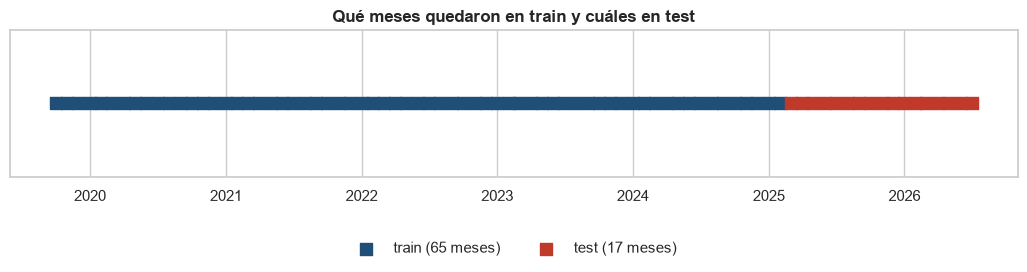

In [11]:
calendario = pd.DataFrame({"fecha": pd.DatetimeIndex(meses_unicos)})
calendario["conjunto"] = np.where(calendario["fecha"].isin(meses_test), "test", "train")

fig, ax = plt.subplots(figsize=(13, 1.9))
for conjunto in ["train", "test"]:
    parte = calendario[calendario["conjunto"] == conjunto]
    ax.scatter(
        parte["fecha"],
        np.zeros(len(parte)),
        marker="s",
        s=70,
        color=COLORES[conjunto],
        label=f"{conjunto} ({len(parte)} meses)",
    )
ax.set_yticks([])
ax.set_title("Qué meses quedaron en train y cuáles en test")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=False)
plt.show()

**División train/test:**
> De los 82 meses (oct-2019 a jul-2026), los 65 más antiguos quedaron en **train**
> (oct-2019 a feb-2025, 195 filas) y los 17 más recientes en **test** (mar-2025 a jul-2026,
> 51 filas). Como la división es cronológica, train no contiene nada posterior a feb-2025; por
> eso algunas variables que empezaron a registrarse hace poco (como el presupuesto, que existe
> desde oct-2025) quedan por completo en test y no se pueden analizar en este EDA.

## 4. Salud general y validación del esquema



In [12]:
filas_por_mes = train.groupby("fecha").size()
print(f"Meses en train: {train['fecha'].nunique()}")
print(f"Rango: {train['fecha'].min():%Y-%m} a {train['fecha'].max():%Y-%m}")
print("Filas por mes (cuántos meses tienen ese número de filas):")
print(filas_por_mes.value_counts().to_string())
print(f"Duplicados mes-proceso: {train.duplicated(['fecha', 'proceso']).sum()}")
print()
display(train["proceso"].value_counts().rename("filas").to_frame())
display(train[COLUMNAS_NUMERICAS].describe().T)

Meses en train: 65
Rango: 2019-10 a 2025-02
Filas por mes (cuántos meses tienen ese número de filas):
3    65
Duplicados mes-proceso: 0



,filas
proceso,
F&A,65
FORMACION,65
LINEA ACABADO PRINCIPAL,65


,count,mean,std,min,25%,50%,75%,max
participacion,195.00,0.67,0.37,0.15,0.15,0.85,1.00,1.00
kwh_total,195.00,"1,257,540.60","213,230.66","498,397.00","1,159,119.00","1,277,520.00","1,383,454.00","1,622,060.00"
kwh_proceso,195.00,"838,360.40","494,539.96","74,759.55","207,855.38","1,063,667.90","1,224,056.88","1,622,060.00"
produccion_eq,99.00,"55,545.94","19,329.64","25,290.00","33,730.54","60,704.04","72,071.79","89,889.00"
kwh_eq_real,195.00,9.38,10.59,0.00,0.00,5.57,18.73,32.62
kwh_eq_presupuesto,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
costo_kwh,39.00,470.80,25.99,443.51,453.10,460.84,475.42,536.46
costo_total,195.00,"78,337,589.33","185,272,416.79",0.00,0.00,0.00,0.00,"654,114,548.52"


### 4.1 Reglas del esquema

Cada columna debería tener estipulado distintos criterios de negocio (por ejemplo, que Formación más Línea
sumen el total F&A). Se verifican una por una, `REVISAR` significa que hay filas que no las
cumplen.

In [13]:
def regla(
    nombre: str,
    cumple: pd.Series | np.ndarray,
    aplica: pd.Series | np.ndarray | None = None,
) -> dict[str, object]:
    """Evalúa una regla de validación sobre los casos (filas o meses) en los que aplica.

    Args:
        nombre: Descripción de la regla.
        cumple: Verdadero en los casos que cumplen la regla.
        aplica: Verdadero en los casos donde la regla tiene sentido; por defecto, todos.

    Returns:
        Diccionario con la regla, los casos evaluados, los que fallan y el resultado.
    """
    cumple_arr = np.asarray(cumple, dtype=bool)
    aplica_arr = np.ones_like(cumple_arr) if aplica is None else np.asarray(aplica, dtype=bool)
    evaluadas = int(aplica_arr.sum())
    fallas = int((aplica_arr & ~cumple_arr).sum())
    return {
        "regla": nombre,
        "casos_evaluados": evaluadas,
        "incumplen": fallas,
        "resultado": "OK" if fallas == 0 else "REVISAR",
    }


PARTICIPACION_ESPERADA = {"FORMACION": 0.85, "LINEA ACABADO PRINCIPAL": 0.15, "F&A": 1.0}
ancho = train.pivot(index="fecha", columns="proceso")
prod_lineas = ancho["produccion_eq"][LINEAS]
hay_prod_lineas = prod_lineas.notna().all(axis=1)
hay_produccion = train["produccion_eq"].notna()
hay_costo = train["costo_kwh"].notna()

reglas = pd.DataFrame(
    [
        regla("3 filas por mes", train.groupby("fecha")["proceso"].transform("size").eq(3)),
        regla("Sin duplicados mes-proceso", ~train.duplicated(["fecha", "proceso"], keep=False)),
        regla(
            "Participación = 0.85 Formación / 0.15 Línea / 1 F&A",
            np.isclose(train["participacion"], train["proceso"].map(PARTICIPACION_ESPERADA)),
        ),
        regla(
            "KWH total igual en las 3 filas del mes",
            train.groupby("fecha")["kwh_total"].transform("nunique").eq(1),
        ),
        regla(
            "KWH por proceso = KWH total x participación",
            pd.Series(
                np.isclose(train["kwh_proceso"], train["kwh_total"] * train["participacion"])
            ),
        ),
        regla(
            "kWh Formación + kWh Línea = kWh F&A",
            pd.Series(
                np.isclose(ancho["kwh_proceso"][LINEAS].sum(axis=1), ancho["kwh_proceso"]["F&A"])
            ),
        ),
        regla(
            "Producción F&A = Producción Formación + Producción Línea",
            pd.Series(np.isclose(prod_lineas.sum(axis=1), ancho["produccion_eq"]["F&A"])),
            aplica=pd.Series(hay_prod_lineas.to_numpy()),
        ),
        regla(
            "KWH/Equ real = kWh por proceso / producción",
            pd.Series(
                np.isclose(train["kwh_eq_real"], train["kwh_proceso"] / train["produccion_eq"])
            ),
            aplica=hay_produccion,
        ),
        regla(
            "Si no hay producción, KWH/Equ real viene en 0 (cero falso)",
            train["kwh_eq_real"].eq(0),
            aplica=~hay_produccion,
        ),
        regla(
            "Costo total = kWh por proceso x costo por kWh",
            pd.Series(np.isclose(train["costo_total"], train["kwh_proceso"] * train["costo_kwh"])),
            aplica=hay_costo,
        ),
        regla(
            "Si no hay costo por kWh, el costo total viene en 0 (cero falso)",
            train["costo_total"].eq(0),
            aplica=~hay_costo,
        ),
        regla(
            "Costo por kWh igual en los 3 procesos del mes",
            train["costo_kwh"].round(6).groupby(train["fecha"]).transform("nunique").le(1),
        ),
        regla(
            "Presupuesto constante dentro de cada proceso",
            train.groupby("proceso")["kwh_eq_presupuesto"].transform("nunique").le(1),
        ),
        regla("Sin valores negativos", (train[COLUMNAS_NUMERICAS].fillna(0) >= 0).all(axis=1)),
    ]
).set_index("regla")
display(reglas)

,casos_evaluados,incumplen,resultado
regla,,,
3 filas por mes,195,0,OK
Sin duplicados mes-proceso,195,0,OK
Participación = 0.85 Formación / 0.15 Línea / 1 F&A,195,0,OK
KWH total igual en las 3 filas del mes,195,0,OK
KWH por proceso = KWH total x participación,195,0,OK
kWh Formación + kWh Línea = kWh F&A,65,0,OK
Producción F&A = Producción Formación + Producción Línea,17,0,OK
KWH/Equ real = kWh por proceso / producción,99,0,OK
"Si no hay producción, KWH/Equ real viene en 0 (cero falso)",96,0,OK


**Hallazgo: El esquema es muy consistente, pero revela cómo se construyeron los datos.**
> Todas las reglas se cumplen. Lo importante es lo que las reglas confirman:
> 1. **Los kWh por línea no se miden, se reparten.** En los 195 casos, `KWH por proceso` es
>    exactamente el total del mes por 0.85 (Formación) o por 0.15 (Línea).
> 2. **La producción F&A es la suma de la producción de las dos líneas** (17 de 17 meses en
>    que existe el dato por línea).
> 3. **Hay "ceros falsos":** cuando falta la producción, el indicador KWH/Equ aparece como 0
>    (96 filas) y cuando falta la tarifa, el costo total aparece como 0 (156 filas). Ese 0 no
>    es un consumo de cero, es un dato faltante (IMPORTANTE).
> 4. La tarifa es la misma para los tres procesos de cada mes. No hay valores negativos ni
>    meses duplicados.

## 5. Valores faltantes

Hay dos tipos de faltantes:

1. **Vacíos visibles** (celdas en blanco).
2. **Ceros falsos:** celdas con `0` que en realidad significan "no hay dato". La sección
   anterior mostró dos casos: el indicador KWH/Equ vale 0 cuando falta la producción, y el
   costo total vale 0 cuando falta la tarifa. Un consumo de 0 kWh por unidad es imposible, así
   que contarlos como ceros reales distorsionaría promedios y gráficos.

In [14]:
ceros_falsos_eq = train["produccion_eq"].isna() & train["kwh_eq_real"].eq(0)
ceros_falsos_costo = train["costo_kwh"].isna() & train["costo_total"].eq(0)

columnas_revisar = ["dia", "turno", *COLUMNAS_NUMERICAS]
faltantes = pd.DataFrame({"vacios": train[columnas_revisar].isna().sum()})
faltantes["ceros_falsos"] = 0
faltantes.loc["kwh_eq_real", "ceros_falsos"] = int(ceros_falsos_eq.sum())
faltantes.loc["costo_total", "ceros_falsos"] = int(ceros_falsos_costo.sum())
faltantes["% faltante real"] = (faltantes["vacios"] + faltantes["ceros_falsos"]) / len(train) * 100
display(faltantes.sort_values("% faltante real", ascending=False))

# Desde aquí los ceros falsos se tratan como lo que son: datos faltantes
train_original = train.copy()
train["kwh_eq_real"] = train["kwh_eq_real"].mask(ceros_falsos_eq)
train["costo_total"] = train["costo_total"].mask(ceros_falsos_costo)

,vacios,ceros_falsos,% faltante real
dia,195,0,100.00
turno,195,0,100.00
kwh_eq_presupuesto,195,0,100.00
costo_kwh,156,0,80.00
costo_total,0,156,80.00
produccion_eq,96,0,49.23
kwh_eq_real,0,96,49.23
kwh_proceso,0,0,0.00
participacion,0,0,0.00
kwh_total,0,0,0.00


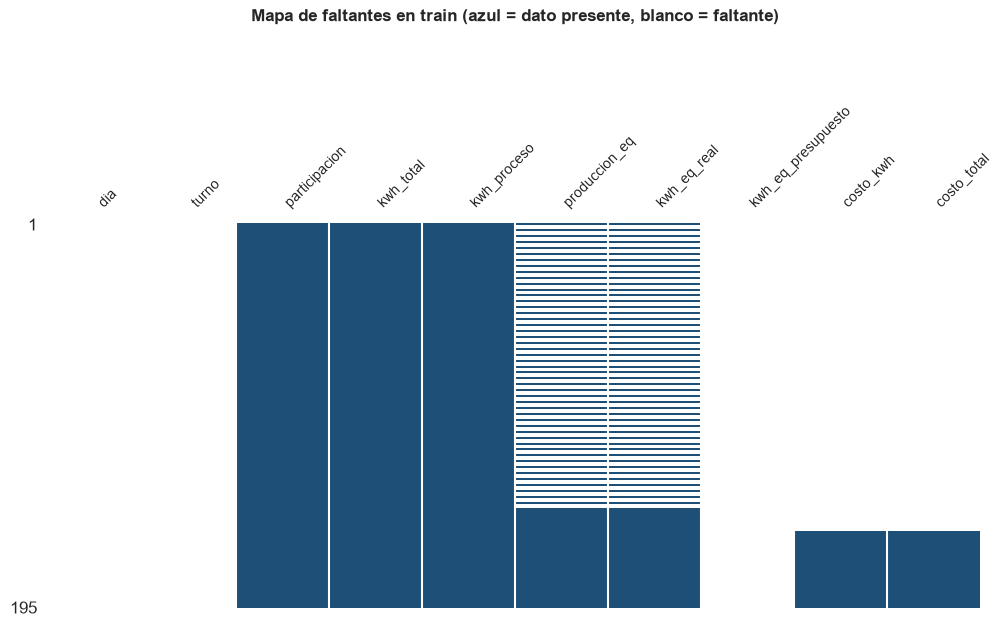

In [15]:
ax = msno.matrix(
    train.sort_values(["fecha", "proceso"])[columnas_revisar],
    figsize=(12, 5),
    fontsize=10,
    sparkline=False,
    color=(0.12, 0.31, 0.47),
)
ax.set_title("Mapa de faltantes en train (azul = dato presente, blanco = faltante)", pad=60)
plt.show()

### 5.1 ¿Desde cuándo existe cada dato?

El mapa anterior sugiere que los faltantes no están regados al azar sino en bloques de tiempo.
El siguiente gráfico muestra, mes a mes, qué datos existen para cada proceso.

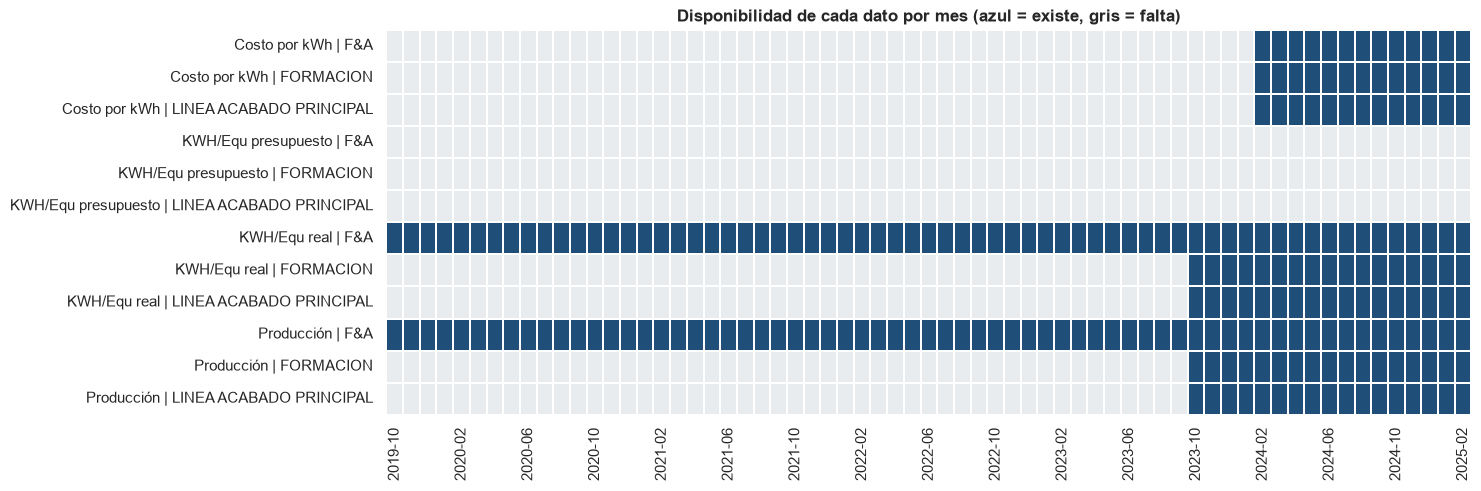

primer_mes ultimo_mes  meses_con_dato
variable      proceso                                                      
costo_kwh     F&A                     2024-02-01 2025-02-01              13
              FORMACION               2024-02-01 2025-02-01              13
              LINEA ACABADO PRINCIPAL 2024-02-01 2025-02-01              13
kwh_eq_real   F&A                     2019-10-01 2025-02-01              65
              FORMACION               2023-10-01 2025-02-01              17
              LINEA ACABADO PRINCIPAL 2023-10-01 2025-02-01              17
produccion_eq F&A                     2019-10-01 2025-02-01              65
              FORMACION               2023-10-01 2025-02-01              17
              LINEA ACABADO PRINCIPAL 2023-10-01 2025-02-01              17

In [16]:
VARIABLES_DISPONIBILIDAD = {
    "produccion_eq": "Producción",
    "kwh_eq_real": "KWH/Equ real",
    "kwh_eq_presupuesto": "KWH/Equ presupuesto",
    "costo_kwh": "Costo por kWh",
}
largo = train.melt(
    id_vars=["fecha", "proceso"],
    value_vars=list(VARIABLES_DISPONIBILIDAD),
    var_name="variable",
    value_name="valor",
)
largo["serie"] = largo["variable"].map(VARIABLES_DISPONIBILIDAD) + " | " + largo["proceso"]
largo["disponible"] = largo["valor"].notna().astype(int)
mapa = largo.pivot_table(index="serie", columns="fecha", values="disponible")

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(mapa, cmap=["#e9ecef", COLORES["F&A"]], cbar=False, linewidths=0.3, ax=ax)
etiquetas = [pd.Timestamp(f).strftime("%Y-%m") for f in mapa.columns]
ax.set_xticks(np.arange(len(etiquetas))[::4] + 0.5, etiquetas[::4], rotation=90)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Disponibilidad de cada dato por mes (azul = existe, gris = falta)")
plt.show()

periodos = (
    largo.dropna(subset=["valor"])
    .groupby(["variable", "proceso"])["fecha"]
    .agg(primer_mes="min", ultimo_mes="max", meses_con_dato="count")
)
display(periodos)

**Hallazgo: Tenemos que los faltantes llegan en bloques de tiempo, no al azar.**
> - **Día y Turno:** 100 % vacíos (dependen de una integración con el SCADA que aún no existe).
> - **Presupuesto (KWH/Equ):** 100 % faltante en train. Solo existe desde oct-2025, que queda
>   completo en test.
> - **Costo por kWh y costo total:** 80 % faltante (contando los ceros falsos). En train solo
>   existe de feb-2024 a feb-2025 (13 meses).
> - **Producción y KWH/Equ por línea:** 49 % faltante. El total F&A tiene producción desde el
>   inicio, pero el detalle por línea solo existe desde oct-2023 (17 meses en train).
>
> En pocas palabras y para resumir un poco, el dato no se perdió, todavía no se registraba. Esto importa porque
> no conviene "inventar" años enteros de producción por línea o de presupuesto; es mejor
> limitar cada análisis al periodo en que el dato existe (ver sección 9).

## 6. Análisis agregado F&A

En esta parte se trabaja solo con las filas `F&A` (el total del área). Los kWh se muestran en
**MWh** (1 MWh = 1.000 kWh) para que las cifras sean más fáciles de leer.

### 6.1 Integridad temporal y frecuencia

Se revisa que el calendario no tenga meses perdidos. Para no espiar el conjunto de test solo
se miran las fechas de ambos conjuntos, nunca sus valores.

In [17]:
calendario_completo = pd.date_range(df["fecha"].min(), df["fecha"].max(), freq="MS")
meses_perdidos = calendario_completo.difference(pd.DatetimeIndex(meses_unicos))
print(f"Calendario esperado: {len(calendario_completo)} meses")
print(f"Meses presentes (train + test): {len(meses_unicos)}")
print(f"Meses que no aparecen en el archivo: {len(meses_perdidos)}")
print(f"Columnas de día y turno con algún dato: {int(train[['dia', 'turno']].notna().any().sum())}")

Calendario esperado: 82 meses
Meses presentes (train + test): 82
Meses que no aparecen en el archivo: 0
Columnas de día y turno con algún dato: 0


**Hallazgo: Hay calendario completo, pero solo mensual.** 
> Los 82 meses entre oct-2019 y jul-2026
> están presentes, sin meses perdidos ni repetidos. La frecuencia es mensual y no hay ningún
> dato de día o turno, es por eso que con esta fuente no se pueden construir reportes diarios
> (que es el objetivo de la plataforma). Para eso hace falta la información del SCADA, como la
> de los rectificadores.

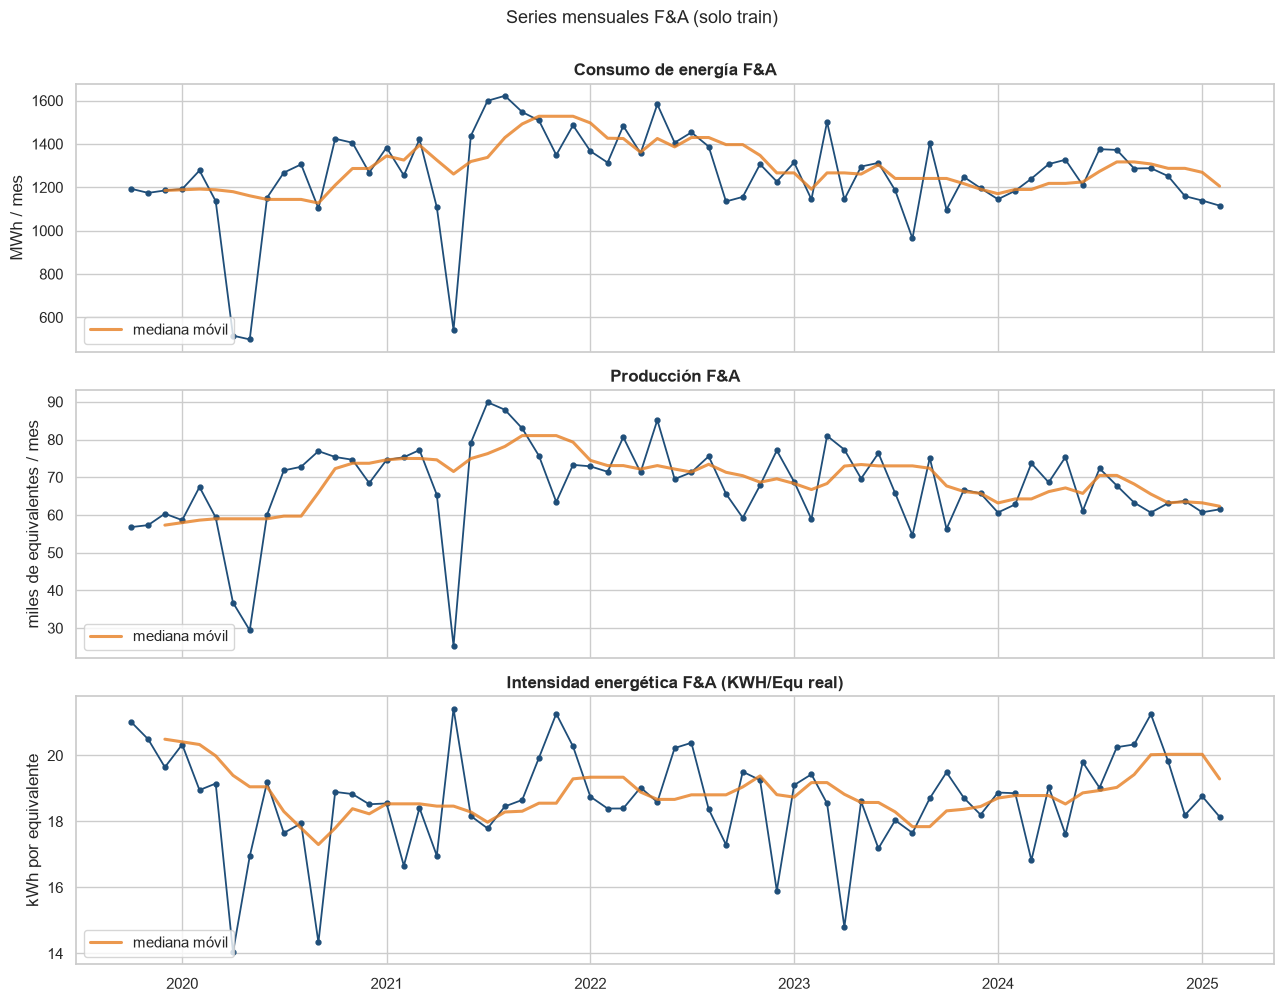

In [18]:
fa = train[train["proceso"] == "F&A"].set_index("fecha").sort_index()
fa["kwh_total_mwh"] = fa["kwh_total"] / 1000
fa["produccion_miles"] = fa["produccion_eq"] / 1000

# Se reindexa al calendario completo: un mes sin dato queda como hueco en la línea
fa_cal = fa.reindex(pd.date_range(fa.index.min(), fa.index.max(), freq="MS"))

SERIES_FA = [
    ("kwh_total_mwh", "Consumo de energía F&A", "MWh / mes"),
    ("produccion_miles", "Producción F&A", "miles de equivalentes / mes"),
    ("kwh_eq_real", "Intensidad energética F&A (KWH/Equ real)", "kWh por equivalente"),
]
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (columna, titulo, unidad) in zip(axes, SERIES_FA, strict=True):
    ax.plot(fa_cal.index, fa_cal[columna], marker="o", ms=3.5, lw=1.3, color=COLORES["F&A"])
    tendencia = fa[columna].rolling(window=6, min_periods=3).median()
    ax.plot(tendencia.index, tendencia, lw=2.2, color="#e67e22", alpha=0.8, label="mediana móvil")
    ax.set_title(titulo)
    ax.set_ylabel(unidad)
    ax.legend(loc="lower left")
fig.suptitle("Series mensuales F&A (solo train)", y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

**Hallazgo: Note que el consumo sigue a la producción casi mes a mes.**
> - El consumo típico de F&A está entre **1.100 y 1.600 MWh por mes**.
> - Hay caídas muy marcadas en abr-may 2020 (~500 MWh) y may-2021 (542 MWh), que
>   coinciden con el confinamiento por COVID-19 y posiblemente, con el paro nacional de 2021
>   (hipótesis a confirmar con planta). También baja ago-2023 (964 MWh).
> - La producción dibuja casi la misma curva que el consumo, por eso la intensidad
>   (kWh por equivalente) se mantiene bastante estable, alrededor de **18-20 kWh/eq**.
> - Los picos de intensidad (~21 kWh/eq) aparecen en may-2021, nov-2021 y oct-2024, y los
>   valores más bajos (~14-15 kWh/eq) en abr-2020, sep-2020 y abr-2023.

### 6.2 Tendencia por año

,meses,consumo_mediano_mwh,produccion_mediana,kwh_eq_mediano
anio,,,,
2019,3,"1,185.31","57,300.00",20.49
2020,12,"1,229.75","67,928.50",18.68
2021,12,"1,429.37","75,492.50",18.50
2022,12,"1,362.04","71,381.50",18.67
2023,12,"1,221.94","67,745.72",18.58
2024,12,"1,268.99","63,496.73",19.03
2025,2,"1,127.18","61,095.39",18.45


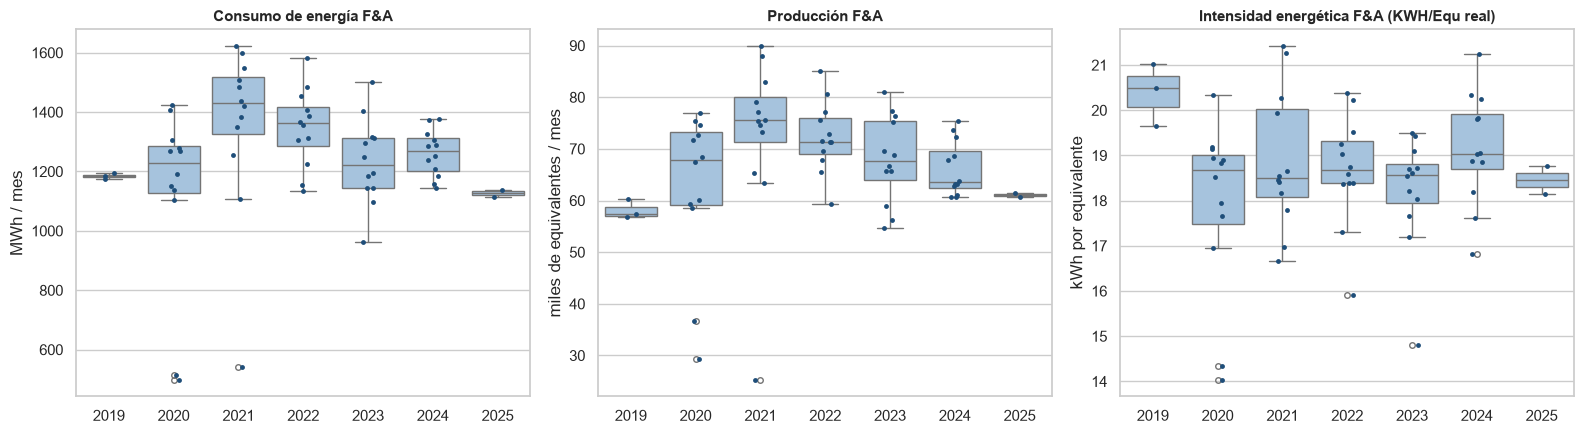

Consumo de energía F&A: rho = -0.03, p = 0.821 -> sin tendencia clara (baja)
Producción F&A: rho = -0.03, p = 0.840 -> sin tendencia clara (baja)
Intensidad energética F&A (KWH/Equ real): rho = +0.02, p = 0.890 -> sin tendencia clara (sube)


In [19]:
fa["anio"] = fa.index.year
resumen_anual = fa.groupby("anio").agg(
    meses=("kwh_total", "size"),
    consumo_mediano_mwh=("kwh_total_mwh", "median"),
    produccion_mediana=("produccion_eq", "median"),
    kwh_eq_mediano=("kwh_eq_real", "median"),
)
display(resumen_anual)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (columna, titulo, unidad) in zip(axes, SERIES_FA, strict=True):
    sns.boxplot(data=fa, x="anio", y=columna, color="#9dc3e6", ax=ax, fliersize=4)
    sns.stripplot(data=fa, x="anio", y=columna, color=COLORES["F&A"], size=3.5, ax=ax)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel(unidad)
plt.tight_layout()
plt.show()

orden_tiempo = fa.index.year + (fa.index.month - 1) / 12
for columna, titulo, _ in SERIES_FA:
    rho, p_valor = stats.spearmanr(orden_tiempo, fa[columna], nan_policy="omit")
    direccion = "sube" if rho > 0 else "baja"
    veredicto = "tendencia clara" if p_valor < ALPHA else "sin tendencia clara"
    print(f"{titulo}: rho = {rho:+.2f}, p = {p_valor:.3f} -> {veredicto} ({direccion})")

**Hallazgo: En train no hay una tendencia de largo plazo; el consumo sube hasta 2021 y luego baja.**
> - El consumo mediano pasó de 1.230 MWh/mes en 2020 a un máximo de **1.429 en 2021**, y
>   después bajó a 1.362 (2022), 1.222 (2023) y 1.269 (2024). Los dos meses de 2025 que están en
>   train (ene y feb) quedan en 1.127. La producción sigue el mismo camino.
> - La prueba de tendencia (Spearman) no encuentra una tendencia clara en ninguna de las tres
>   series (p > 0.8): la subida hasta 2021 y la bajada posterior se compensan.
> - La intensidad se mantiene estable (mediana anual entre 18.5 y 19 kWh/eq), es decir, la
>   eficiencia no mejora ni empeora de forma sostenida en el periodo de train.
> - Como test es el periodo más reciente (desde mar-2025), cualquier modelo tendrá que estar
>   preparado para cambios de nivel en el consumo.

### 6.3 Estacionalidad

¿Hay meses del año que consumen sistemáticamente más o menos? Como el consumo también cambia
de un año a otro, se usa un índice estacional, el valor del mes dividido entre la mediana
de su año. Un índice de 1.10 significa "10 % por encima de lo normal en ese año".

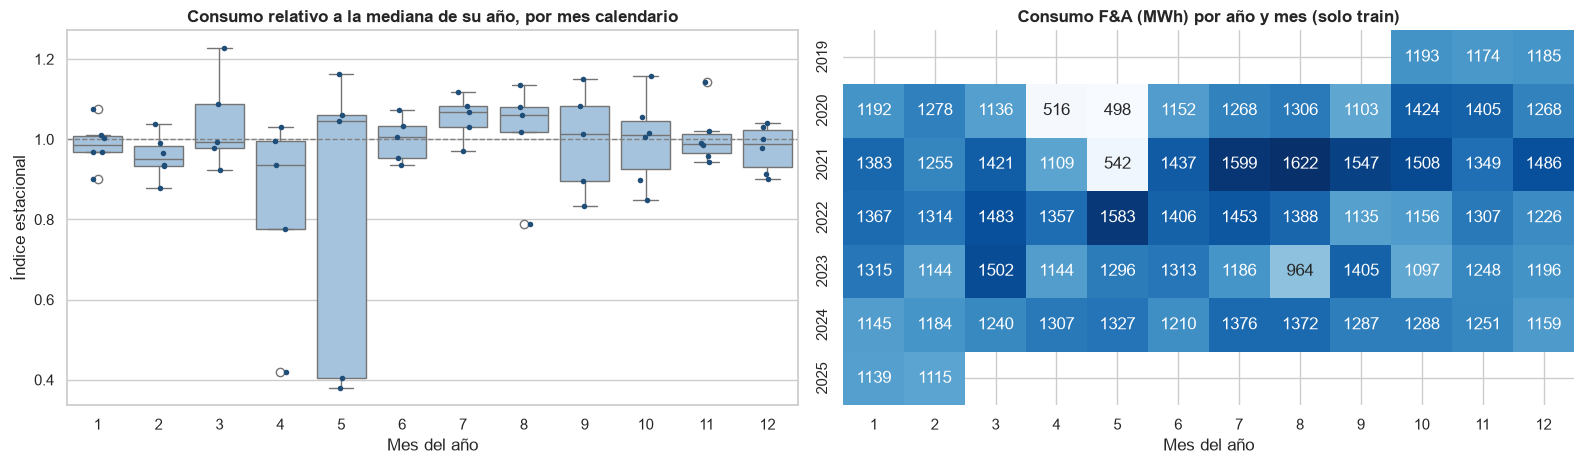

Prueba de Kruskal-Wallis entre meses: H = 9.17, p = 0.606
-> No se detecta un patrón estacional estadísticamente claro


In [20]:
fa["mes_num"] = fa.index.month
fa["indice_estacional"] = fa["kwh_total"] / fa.groupby("anio")["kwh_total"].transform("median")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.boxplot(data=fa, x="mes_num", y="indice_estacional", color="#9dc3e6", ax=axes[0])
sns.stripplot(data=fa, x="mes_num", y="indice_estacional", color=COLORES["F&A"], size=4, ax=axes[0])
axes[0].axhline(1, color="grey", ls="--", lw=1)
axes[0].set_title("Consumo relativo a la mediana de su año, por mes calendario")
axes[0].set_xlabel("Mes del año")
axes[0].set_ylabel("Índice estacional")

tabla_anio_mes = fa.pivot_table(index="anio", columns="mes_num", values="kwh_total_mwh")
sns.heatmap(tabla_anio_mes, annot=True, fmt=".0f", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set_title("Consumo F&A (MWh) por año y mes (solo train)")
axes[1].set_xlabel("Mes del año")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

grupos = [g["indice_estacional"].to_numpy() for _, g in fa.groupby("mes_num")]
h_estadistico, p_valor = stats.kruskal(*grupos)
print(f"Prueba de Kruskal-Wallis entre meses: H = {h_estadistico:.2f}, p = {p_valor:.3f}")
print(
    "-> Hay diferencias significativas entre meses"
    if p_valor < ALPHA
    else "-> No se detecta un patrón estacional estadísticamente claro"
)

**Hallazgo: Técnicamente, no hay una estacionalidad clara.**
> La prueba de Kruskal-Wallis no encuentra
> diferencias significativas entre meses del año (p = 0.61). Julio y agosto tienden a quedar un
> poco por encima de lo normal (alrededor de +6 %), pero con unos 5 datos por cada mes del año
> no es concluyente. Las caídas de abril y mayo se deben a eventos puntuales (2020 y 2021), no a
> un patrón que se repita cada año (la producción y los eventos especiales pesan mucho más que
> el mes del año).

### 6.4 Distribuciones

Para cada variable se muestra el histograma, el diagrama de caja y el gráfico Q-Q (que compara
los datos con una distribución normal; si los puntos siguen la línea, la variable se comporta
"normal"). Se usa la función `normality_report` del equipo.

=== Consumo de energía F&A ===


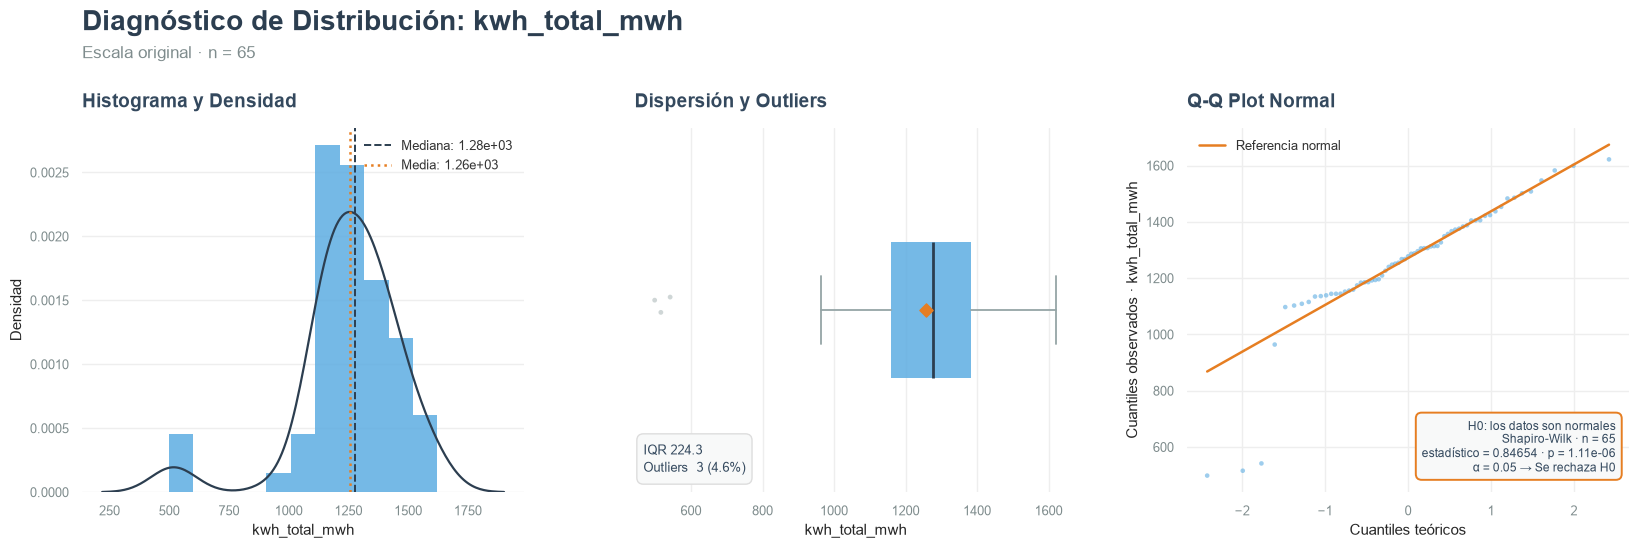

=== Producción F&A ===


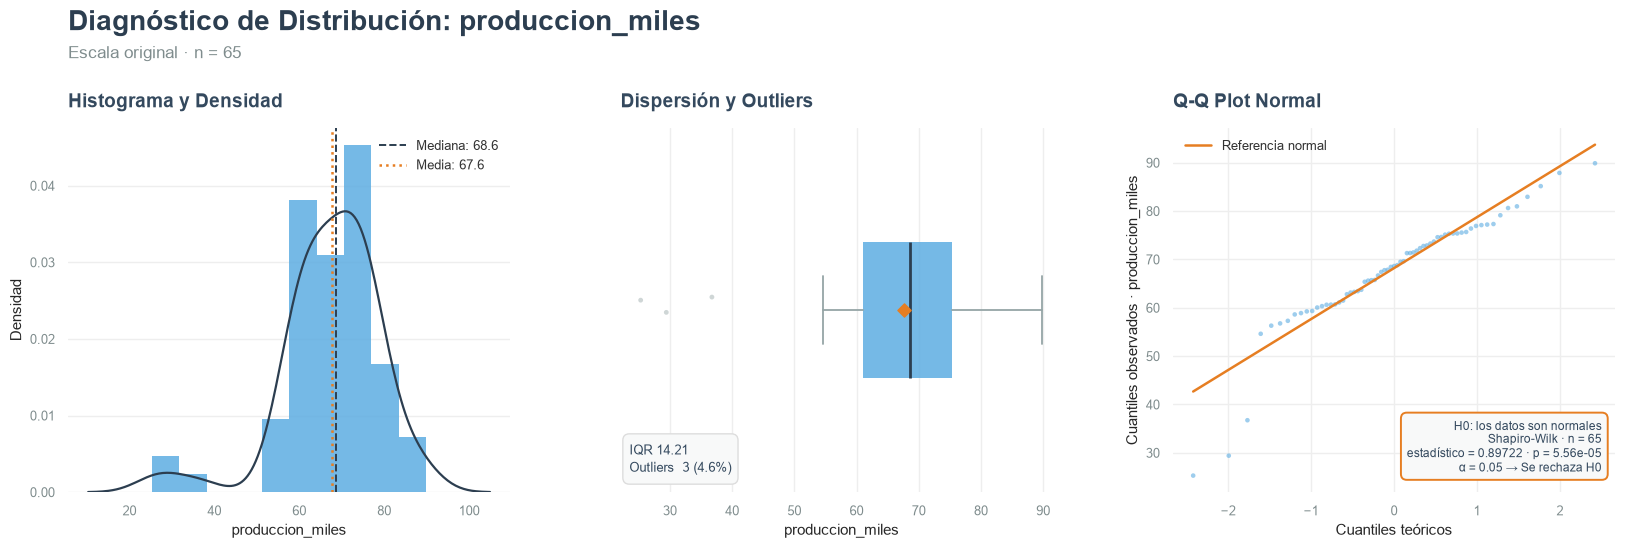

=== Intensidad energética F&A (KWH/Equ real) ===


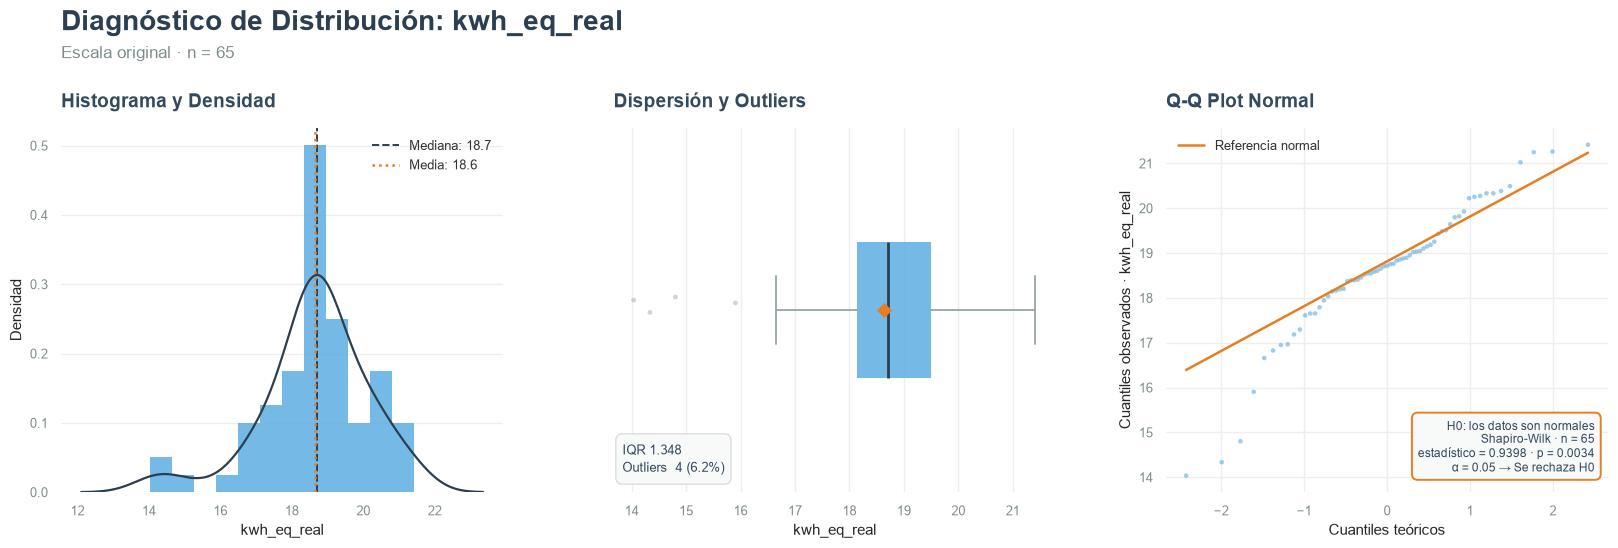

,n,mean,median,skew,p_value,is_normal
Consumo de energía F&A,65,"1,257.54","1,277.52",-1.67,0.00,False
Producción F&A,65,67.62,68.63,-1.36,0.00,False
Intensidad energética F&A (KWH/Equ real),65,18.64,18.71,-0.86,0.00,False


In [21]:
fa_plano = fa.reset_index(drop=True)
resultados_normalidad = {}
for columna, titulo, _ in SERIES_FA:
    print(f"=== {titulo} ===")
    resultado = normality_report(fa_plano, columna, random_state=RANDOM_STATE)
    resultados_normalidad[titulo] = {
        clave: resultado.get(clave)
        for clave in ["n", "mean", "median", "skew", "p_value", "is_normal"]
    }
aplicar_estilo()
display(pd.DataFrame(resultados_normalidad).T)

**Hallazgo: Ninguna variable es "normal", por culpa de unos pocos meses muy bajos.**
> - Las tres variables tienen una cola hacia la izquierda (asimetría negativa: -1.67 en
>   consumo, -1.36 en producción, -0.86 en intensidad) y la prueba de Shapiro-Wilk rechaza la
>   normalidad en las tres.
> - Aun así, media y mediana son muy parecidas (consumo: 1.258 vs 1.278 MWh), lo que indica que
>   el "grueso" de los datos es simétrico y que la forma la deforman los meses atípicos.
> - Para resumir y comparar conviene usar medianas y métodos
>   robustos (en el modelo tratar los meses extraordinarios de forma explícita).

### 6.5 Valores atípicos

Medidas de detección:

- Regla del rango intercuartílico (IQR)
- Puntaje z robusto (por encima de 3.5 se considera atípico)

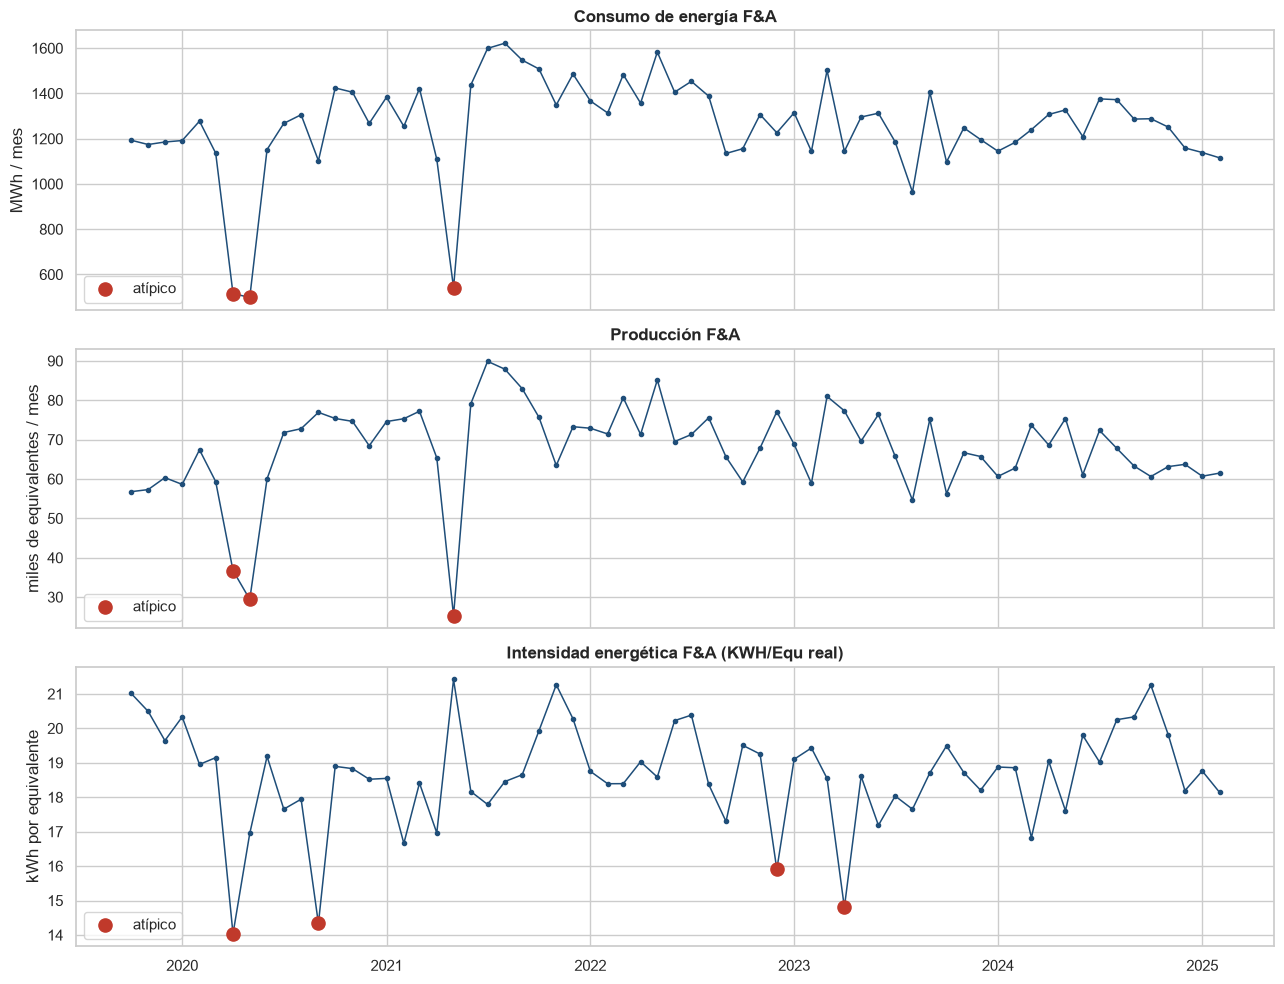

valor  z_robusto  fuera_iqr  \
variable                                 fecha                                  
Consumo de energía F&A                   2020-04 515.68      -4.65       True   
                                         2020-05 498.40      -4.76       True   
                                         2021-05 541.65      -4.49       True   
Producción F&A                           2020-04  36.74      -3.19       True   
                                         2020-05  29.41      -3.93       True   
                                         2021-05  25.29      -4.34       True   
Intensidad energética F&A (KWH/Equ real) 2020-04  14.04      -4.42       True   
                                         2020-09  14.33      -4.14       True   
                                         2022-12  15.91      -2.65       True   
                                         2023-04  14.80      -3.70       True   

                                                  fuera_z  
variable                                 fecha             
Consumo de energía F&A                   2020-04     True  
                                         2020-05     True  
                                         2021-05     True  
Producción F&A                           2020-04    False  
                                         2020-05     True  
                                         2021-05     True  
Intensidad energética F&A (KWH/Equ real) 2020-04     True  
                                         2020-09     True  
                                         2022-12    False  
                                         2023-04     True

In [22]:
FACTOR_IQR = 1.5
Z_ROBUSTO_MAX = 3.5
CONSTANTE_MAD = 0.6745


def detectar_atipicos(serie: pd.Series) -> pd.DataFrame:
    """Marca valores atípicos con la regla IQR y con el puntaje z robusto (MAD).

    Args:
        serie: Valores numéricos a evaluar; los vacíos se ignoran.

    Returns:
        Tabla con el valor, el puntaje z robusto y una marca por cada regla.
    """
    valores = serie.dropna()
    q1, q3 = valores.quantile([0.25, 0.75])
    ancho_caja = q3 - q1
    limite_inf, limite_sup = q1 - FACTOR_IQR * ancho_caja, q3 + FACTOR_IQR * ancho_caja
    mediana = valores.median()
    mad = (valores - mediana).abs().median()
    z_robusto = CONSTANTE_MAD * (valores - mediana) / mad
    return pd.DataFrame(
        {
            "valor": valores,
            "z_robusto": z_robusto,
            "fuera_iqr": (valores < limite_inf) | (valores > limite_sup),
            "fuera_z": z_robusto.abs() > Z_ROBUSTO_MAX,
        }
    )


tablas = []
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (columna, titulo, unidad) in zip(axes, SERIES_FA, strict=True):
    marcas = detectar_atipicos(fa[columna])
    atipicos = marcas[marcas["fuera_iqr"] | marcas["fuera_z"]]
    tablas.append(atipicos.assign(variable=titulo))
    ax.plot(fa_cal.index, fa_cal[columna], marker="o", ms=3, lw=1.1, color=COLORES["F&A"])
    ax.scatter(
        atipicos.index, atipicos["valor"], s=90, color=COLORES["atipico"], zorder=3, label="atípico"
    )
    ax.set_title(titulo)
    ax.set_ylabel(unidad)
    ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

tabla_atipicos = pd.concat(tablas).reset_index(names="fecha")
tabla_atipicos["fecha"] = tabla_atipicos["fecha"].dt.strftime("%Y-%m")
display(tabla_atipicos.set_index(["variable", "fecha"]))

**Hallazgo: Los atípicos parecen eventos reales, no errores de digitación.**
> - **Consumo:** abr-2020, may-2020 y may-2021 (marcados por ambas reglas).
> - **Producción:** los mismos tres meses: abr-2020 (solo IQR), may-2020 y may-2021.
> - **Intensidad:** valores muy bajos en abr-2020 (14.0), sep-2020 (14.3) y abr-2023 (14.8),
>   marcados por ambas reglas, y dic-2022 (15.9), solo por IQR.

### 6.6 Relación entre energía y producción

Si la energía dependiera solo de cuánto se produce, los puntos formarían una línea. El punto
de corte de esa línea con el eje (producción = 0) se interpreta como un consumo base, la
energía que se gasta aunque no se produzca nada (iluminación, compresores, equipos en espera).

Correlación (r): 0.90 | R2: 0.81 | meses: 65
Consumo base estimado: 124 MWh/mes
Energía adicional por cada equivalente producido: 16.8 kWh


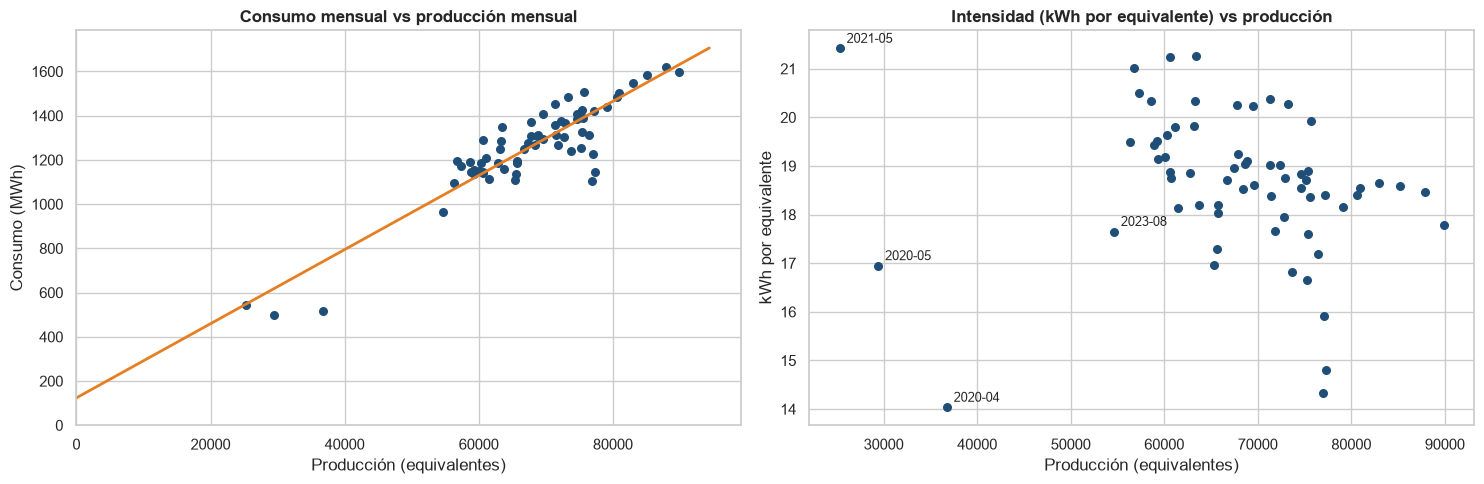

In [23]:
relacion = fa.dropna(subset=["produccion_eq", "kwh_total"])
ajuste = stats.linregress(relacion["produccion_eq"], relacion["kwh_total"])
print(f"Correlación (r): {ajuste.rvalue:.2f} | R2: {ajuste.rvalue**2:.2f} | meses: {len(relacion)}")
print(f"Consumo base estimado: {ajuste.intercept / 1000:,.0f} MWh/mes")
print(f"Energía adicional por cada equivalente producido: {ajuste.slope:,.1f} kWh")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x_linea = np.linspace(0, relacion["produccion_eq"].max() * 1.05, 50)
axes[0].scatter(relacion["produccion_eq"], relacion["kwh_total_mwh"], color=COLORES["F&A"], s=30)
axes[0].plot(x_linea, (ajuste.intercept + ajuste.slope * x_linea) / 1000, color="#e67e22", lw=2)
axes[0].set_xlim(left=0)
axes[0].set_ylim(bottom=0)
axes[0].set_title("Consumo mensual vs producción mensual")
axes[0].set_xlabel("Producción (equivalentes)")
axes[0].set_ylabel("Consumo (MWh)")

axes[1].scatter(relacion["produccion_eq"], relacion["kwh_eq_real"], color=COLORES["F&A"], s=30)
axes[1].set_title("Intensidad (kWh por equivalente) vs producción")
axes[1].set_xlabel("Producción (equivalentes)")
axes[1].set_ylabel("kWh por equivalente")
for fecha, fila in relacion.nsmallest(4, "produccion_eq").iterrows():
    axes[1].annotate(
        f"{fecha:%Y-%m}",
        (fila["produccion_eq"], fila["kwh_eq_real"]),
        textcoords="offset points",
        xytext=(5, 4),
        fontsize=9,
    )
plt.tight_layout()
plt.show()

**Hallazgo: La producción explica el 81 % de las variaciones del consumo.**
> - La correlación entre producción y consumo es r = 0.90 (R² = 0.81).
> - La línea de ajuste sugiere un consumo base de unos 124 MWh/mes (cerca del 10 % de un mes
>   típico) que se gasta aunque no se produzca, y unos **16.8 kWh adicionales por cada
>   equivalente** producido.
> - El gráfico de la derecha muestra que los meses con producción baja son los que tienen la
>   intensidad más "rara" (muy alta o muy baja). **Ojo:** comparar el KPI de intensidad entre
>   meses con producciones muy distintas puede ser injusto; un modelo de línea base
>   (consumo esperado según la producción) es una mejor referencia que la intensidad sola.

## 7. Formación vs Línea de Acabado Principal

### 7.1 ¿Los kWh de cada línea son medidos o repartidos?

La validación del esquema mostró que `KWH por proceso` es siempre el total del mes
multiplicado por un porcentaje fijo.

,minimo,maximo,valores_distintos
proceso,,,
FORMACION,0.85,0.85,1
LINEA ACABADO PRINCIPAL,0.15,0.15,1


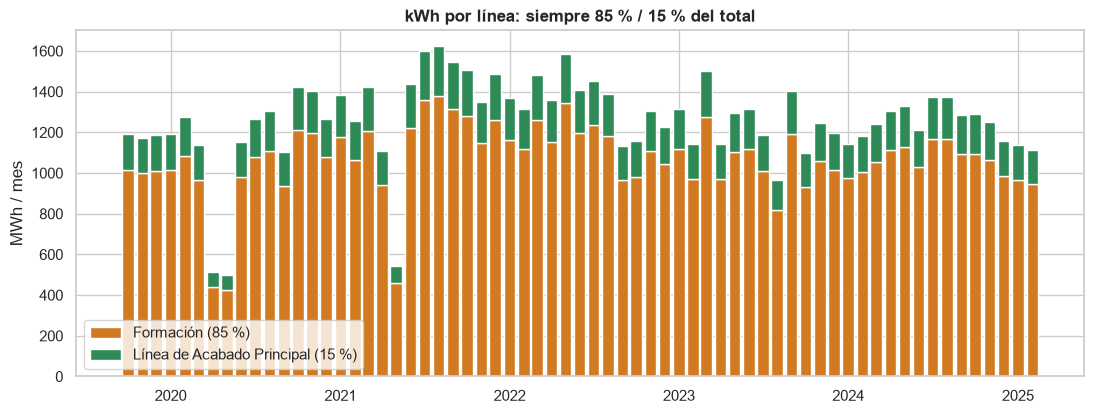

In [24]:
lineas = train[train["proceso"].isin(LINEAS)].copy()
lineas["proporcion_kwh"] = (lineas["kwh_proceso"] / lineas["kwh_total"]).round(6)
display(
    lineas.groupby("proceso")["proporcion_kwh"].agg(
        minimo="min", maximo="max", valores_distintos="nunique"
    )
)

kwh_lineas = (
    lineas.pivot(index="fecha", columns="proceso", values="kwh_proceso").reindex(
        pd.date_range(fa.index.min(), fa.index.max(), freq="MS")
    )
    / 1000
)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(
    kwh_lineas.index,
    kwh_lineas["FORMACION"],
    width=25,
    color=COLORES["FORMACION"],
    label="Formación (85 %)",
)
ax.bar(
    kwh_lineas.index,
    kwh_lineas["LINEA ACABADO PRINCIPAL"],
    width=25,
    bottom=kwh_lineas["FORMACION"],
    color=COLORES["LINEA ACABADO PRINCIPAL"],
    label="Línea de Acabado Principal (15 %)",
)
ax.set_title("kWh por línea: siempre 85 % / 15 % del total")
ax.set_ylabel("MWh / mes")
ax.legend(loc="lower left")
plt.show()

 **Hallazgo: Los kWh por línea son un reparto fijo, no una medición.** 
> En todos los meses
> de train, Formación recibe exactamente el 85 % y la Línea de Acabado el 15 % del
> consumo total (un único valor distinto en cada caso). Esto tiene como consecuencias:
> - Cualquier gráfico o modelo de "kWh por línea" solo repite el total multiplicado por una
>   constante; no aporta información nueva.
> - El KPI de intensidad por línea (kWh/eq) depende por completo de ese supuesto 85/15. Si el
>   reparto real fuera otro, los KPI por línea estarían sesgados.
> - Esto contradice la nota del Excel ("este dato se toma desde el SCADA"): hoy no se toma de
>   ahí. 

### 7.2 Producción por línea

La producción por línea es el dato que en si distingue a Formación de la Línea de Acabado. Solo
existe desde octubre de 2023, así que la comparación entre líneas se hace en ese periodo.

Periodo con producción por línea en train: 2023-10 en adelante (17 meses)


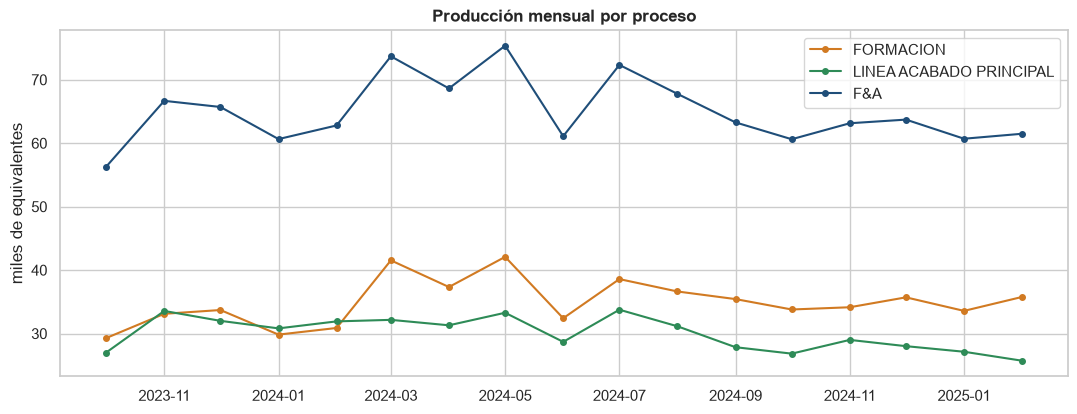

Formación aporta en promedio el 53.7% de la producción F&A (rango 49.2% - 58.2%)


In [25]:
INICIO_LINEAS = lineas.dropna(subset=["produccion_eq"])["fecha"].min()
reciente = train[train["fecha"] >= INICIO_LINEAS].copy()
print(
    f"Periodo con producción por línea en train: {INICIO_LINEAS:%Y-%m} en adelante "
    f"({reciente['fecha'].nunique()} meses)"
)

prod_reciente = (
    reciente.pivot(index="fecha", columns="proceso", values="produccion_eq").reindex(
        pd.date_range(INICIO_LINEAS, reciente["fecha"].max(), freq="MS")
    )
    / 1000
)
fig, ax = plt.subplots(figsize=(13, 4.5))
for proceso in PROCESOS:
    ax.plot(
        prod_reciente.index,
        prod_reciente[proceso],
        marker="o",
        ms=4,
        lw=1.5,
        color=COLORES[proceso],
        label=proceso,
    )
ax.set_title("Producción mensual por proceso")
ax.set_ylabel("miles de equivalentes")
ax.legend()
plt.show()

participacion_prod = (prod_reciente["FORMACION"] / prod_reciente["F&A"]).dropna()
print(
    f"Formación aporta en promedio el {participacion_prod.mean():.1%} de la producción F&A "
    f"(rango {participacion_prod.min():.1%} - {participacion_prod.max():.1%})"
)

**Hallazgo: La producción por línea sí es información real (desde oct-2023).**
> - En los 17 meses de train con este dato, Formación aporta en promedio el 53.7 % de la
>   producción F&A (entre 49 % y 58 %), y la Línea de Acabado el resto.
> - Ambas líneas suben y bajan juntas, lo que tiene sentido si las baterías pasan primero por
>   Formación y luego por Acabado. Desde mar-2024 Formación produce siempre más que la Línea, y
>   la diferencia se amplía hacia finales de 2024.

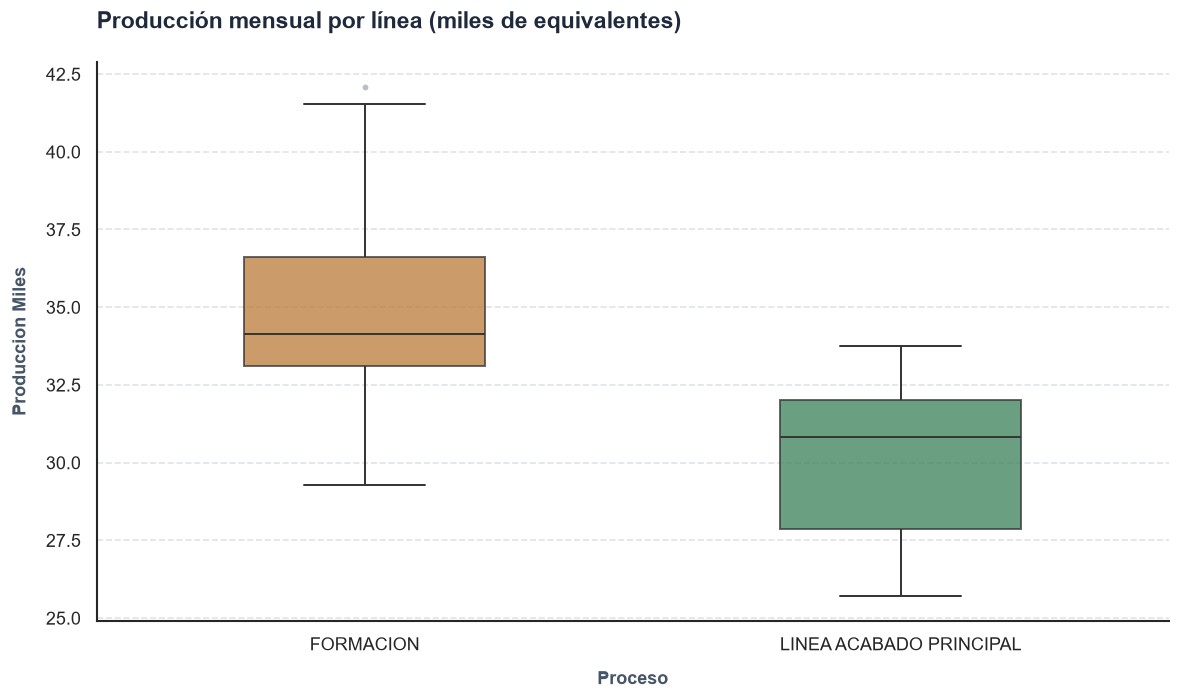

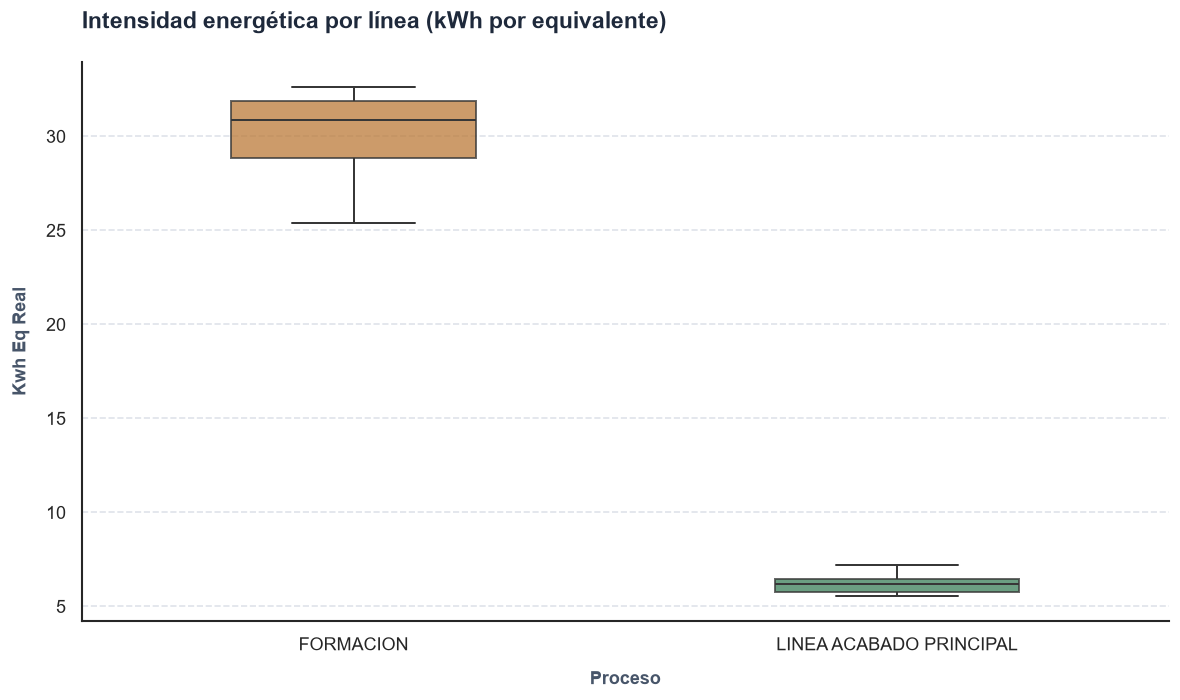

proceso              FORMACION  LINEA ACABADO PRINCIPAL
produccion_eq count      17.00                    17.00
              mean   34,929.60                30,009.55
              std     3,600.82                 2,626.43
              min    29,290.00                25,717.79
              25%    33,112.57                27,847.30
              50%    34,144.28                30,813.76
              75%    36,629.91                32,000.70
              max    42,084.82                33,755.13
kwh_eq_real   count      17.00                    17.00
              mean       30.14                     6.18
              std         2.32                     0.48
              min        25.38                     5.56
              25%        28.84                     5.78
              50%        30.87                     6.21
              75%        31.85                     6.47
              max        32.62                     7.20

In [26]:
reciente_lineas = reciente[reciente["proceso"].isin(LINEAS)].copy()
reciente_lineas["produccion_miles"] = reciente_lineas["produccion_eq"] / 1000
plot_segmented_boxplot(
    reciente_lineas,
    num_col="produccion_miles",
    cat_col="proceso",
    palette=[COLORES[p] for p in LINEAS],
    title="Producción mensual por línea (miles de equivalentes)",
    x_rotation=0,
)
plot_segmented_boxplot(
    reciente_lineas,
    num_col="kwh_eq_real",
    cat_col="proceso",
    palette=[COLORES[p] for p in LINEAS],
    title="Intensidad energética por línea (kWh por equivalente)",
    x_rotation=0,
)
aplicar_estilo()
display(reciente_lineas.groupby("proceso")[["produccion_eq", "kwh_eq_real"]].describe().T)

**Hallazgo: Podemos ver que las dos líneas son muy diferentes en intensidad.**
> - Producción: Formación produce más (mediana ~34.100 equivalentes/mes) que la Línea de
>   Acabado (~30.800). Formación tiene un mes alto marcado como atípico (may-2024, ~42.100).
> - Intensidad: Formación gasta unos 31 kWh por equivalente (entre 25.4 y 32.6), mientras
>   que la Línea gasta 6.2 (entre 5.6 y 7.2). Formación es claramente el proceso que más
>   energía consume, lo cual es esperable porque ahí se cargan eléctricamente las baterías.
> - Recordar que estas intensidades salen del reparto 85/15: la diferencia entre líneas es real
>   en dirección, pero su tamaño exacto depende de ese supuesto.

### 7.3 Intensidad energética real vs presupuesto

**Nota:** El presupuesto (meta de kWh por equivalente) solo existe desde octubre de 2025. Con
la división temporal esos meses quedan **completos en test**, así que la comparación contra la
meta no se puede hacer en este EDA sin espiar el conjunto de test. Se verifica:

In [27]:
print(f"Meses de train con presupuesto: {train['kwh_eq_presupuesto'].notna().sum()}")
print(f"Último mes de train: {train['fecha'].max():%Y-%m}")

Meses de train con presupuesto: 0
Último mes de train: 2025-02


**Hallazgo: El presupuesto no se puede evaluar con los datos de train.**
> Train no tiene ningún mes con presupuesto (termina en feb-2025 y la meta empieza en
> oct-2025). La comparación real vs meta queda para la etapa de evaluación del modelo, cuando se
> use el conjunto de test.

**Algo que se podría tomar en cuenta**
> Al hacer esa comparación, revisar con qué reparto se construyeron las metas por línea: si no
> usan el mismo 85/15 de los datos reales, la comparación por línea no sería justa y solo la de
> F&A total tendría sentido.

### 7.4 ¿Qué producción explica mejor el consumo total?

Como los kWh por línea son repartidos y no medidos, se compara el consumo total medido con
la producción de cada línea. Si una de ellas sigue mejor al consumo, es una pista de dónde se
concentra realmente la energía (con pocos meses, es solo una pista).

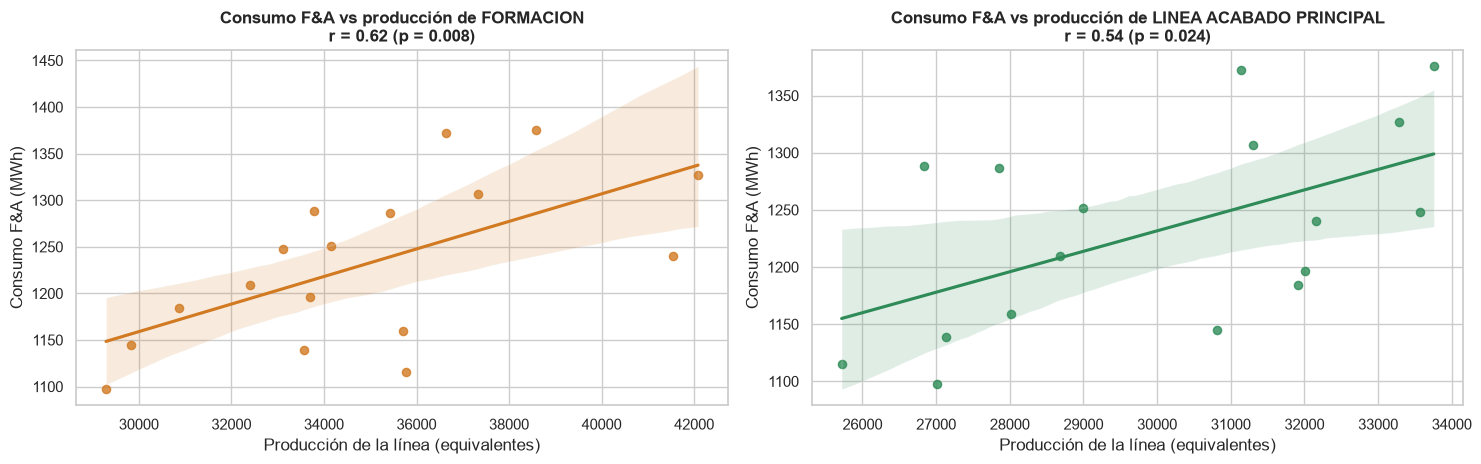

In [28]:
total_vs_lineas = ancho.loc[ancho.index >= INICIO_LINEAS]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, proceso in zip(axes, LINEAS, strict=True):
    x = total_vs_lineas["produccion_eq"][proceso]
    y = total_vs_lineas["kwh_total"]["F&A"] / 1000
    validos = x.notna() & y.notna()
    r, p_valor = stats.pearsonr(x[validos], y[validos])
    sns.regplot(x=x[validos], y=y[validos], ax=ax, color=COLORES[proceso], scatter_kws={"s": 35})
    ax.set_title(f"Consumo F&A vs producción de {proceso}\nr = {r:.2f} (p = {p_valor:.3f})")
    ax.set_xlabel("Producción de la línea (equivalentes)")
    ax.set_ylabel("Consumo F&A (MWh)")
plt.tight_layout()
plt.show()

**Hallazgo: Con datos mensuales no se puede saber qué línea "manda" en el consumo.**
> El consumo total se relaciona de forma moderada tanto con la producción de Formación
> (r = 0.62) como con la de la Línea (r = 0.54), con solo 17 meses de datos. Formación queda un
> poco por encima, pero la diferencia no es concluyente porque las dos producciones se mueven
> juntas. Para separar el consumo real de cada línea hace falta medirlo por separado (por
> ejemplo, con los contadores de los rectificadores de Formación del SCADA).

## 8. Costos

El costo por kWh es la tarifa de energía de cada mes (probablemente en pesos colombianos,
COP). El costo total es consumo por tarifa.

Meses de train con tarifa: 13 de 65
Tarifa mínima: 443.5 | máxima: 536.5


,size,median,min,max
anio,,,,
2024,11,460.72,443.51,481.92
2025,2,524.80,513.14,536.46


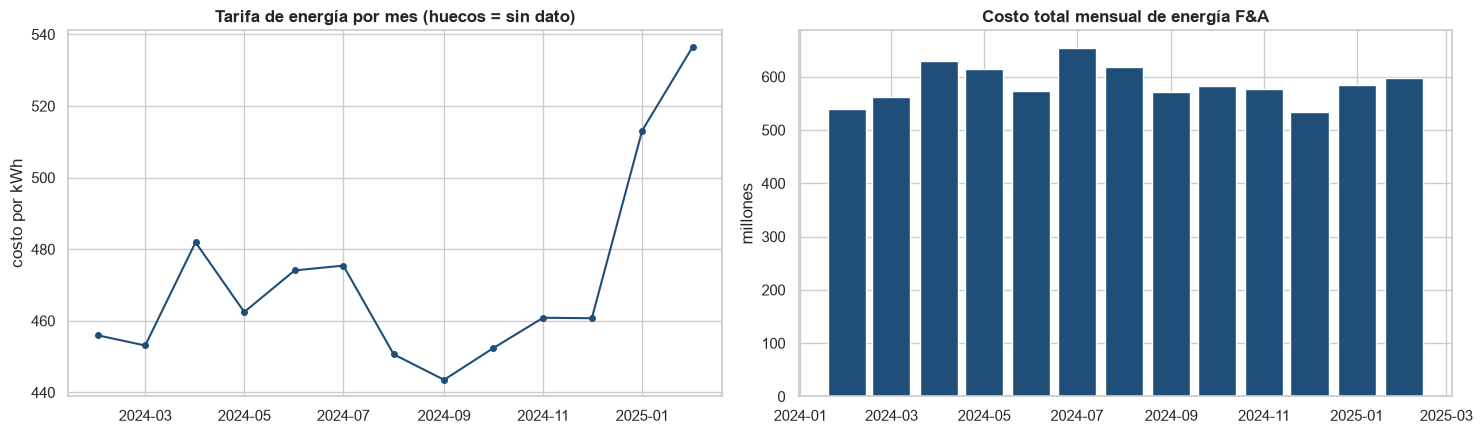

In [29]:
costos = fa.dropna(subset=["costo_kwh"])
print(f"Meses de train con tarifa: {len(costos)} de {len(fa)}")
print(f"Tarifa mínima: {costos['costo_kwh'].min():,.1f} | máxima: {costos['costo_kwh'].max():,.1f}")
display(costos.groupby("anio")["costo_kwh"].agg(["size", "median", "min", "max"]))

repetidas = costos["costo_kwh"].round(6).duplicated(keep=False)
if repetidas.any():
    print("Meses con exactamente la misma tarifa que otro mes:")
    print(costos.loc[repetidas, "costo_kwh"].to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(fa_cal.index, fa_cal["costo_kwh"], marker="o", ms=4, color=COLORES["F&A"])
axes[0].set_title("Tarifa de energía por mes (huecos = sin dato)")
axes[0].set_ylabel("costo por kWh")
axes[1].bar(fa_cal.index, fa_cal["costo_total"] / 1e6, width=25, color=COLORES["F&A"])
axes[1].set_title("Costo total mensual de energía F&A")
axes[1].set_ylabel("millones")
plt.tight_layout()
plt.show()

**Hallazgo: La energía se encareció al iniciar 2025.**
> - Solo 13 de los 65 meses de train tienen tarifa (feb-2024 a feb-2025).
> - La tarifa mediana de 2024 fue de 461 por kWh. En ene-2025 y feb-2025 subió a 513 y 536,
>   entre un 11 % y un 16 % por encima de la mediana de 2024.
> - El costo mensual de energía de F&A en train está entre 534 y 654 millones (probablemente
>   COP). Por el aumento de la tarifa, el costo no baja aunque el consumo de inicios de 2025 sea
>   de los más bajos del periodo.

### 8.1 ¿La tarifa es de toda la planta?

Si la tarifa es la misma para todas las áreas, las otras hojas del archivo podrían servir para
llenar los meses que faltan en F&A. Se comparan solo los meses de train.

In [30]:
def tarifa_por_mes(hoja: str) -> pd.Series:
    """Extrae la tarifa de energía por mes de otra hoja del mismo archivo.

    Args:
        hoja: Nombre de la hoja del Excel.

    Returns:
        Tarifa por mes (índice = primer día del mes); si un mes aparece varias veces se toma
        el primer valor no vacío.
    """
    crudo = datos_por_hoja[hoja]
    tabla = crudo.iloc[1:].copy()
    tabla.columns = [" ".join(str(c).split()) for c in crudo.iloc[0]]
    tabla = tabla[tabla["Mes"].isin(list(MESES))]
    fechas = pd.to_datetime(
        pd.DataFrame(
            {"year": pd.to_numeric(tabla["Año"]), "month": tabla["Mes"].map(MESES), "day": 1}
        )
    )
    tarifa = pd.to_numeric(tabla["Costo por KWH"], errors="coerce")
    return tarifa.groupby(fechas.to_numpy()).first()


tarifas = pd.DataFrame(
    {"F&A": fa["costo_kwh"], "Ensamble": tarifa_por_mes("Ensamble"), "OREC": tarifa_por_mes("OREC")}
).reindex(fa.index)
tarifas = tarifas.dropna(how="all")
tarifas["coinciden"] = tarifas.round(4).nunique(axis=1).eq(1)
tarifas.index = tarifas.index.strftime("%Y-%m")
display(tarifas)
print(f"Meses de train con tarifa en alguna hoja: {len(tarifas)}")
print(f"Meses donde las hojas no coinciden: {int((~tarifas['coinciden']).sum())}")

,F&A,Ensamble,OREC,coinciden
fecha,,,,
2024-02,455.92,455.92,455.92,True
2024-03,453.10,453.10,453.10,True
2024-04,481.92,481.92,481.92,True
2024-05,462.45,462.45,462.45,True
2024-06,474.07,474.07,474.07,True
2024-07,475.42,475.42,475.42,True
2024-08,450.63,450.63,450.63,True
2024-09,443.51,443.51,443.51,True
2024-10,452.28,452.28,452.28,True


Meses de train con tarifa en alguna hoja: 13
Meses donde las hojas no coinciden: 0


**Hallazgo: La tarifa es de toda la planta.**
> En los 13 meses de train con tarifa, F&A, Ensamble y OREC tienen exactamente la misma tarifa.
> Esto permite usar cualquiera de las hojas como fuente de la tarifa, pero también indica que
> las otras hojas no sirven para llenar los meses sin tarifa en F&A (les faltan los mismos
> meses).

## 9. Estrategia de valores faltantes

Esta sección **documenta** qué hacer con cada faltante. Las decisiones finales de imputación se
toman cuando se defina el modelo, y cualquier valor que se calcule para llenar huecos (una
mediana, una interpolación) debe calcularse **solo con train** para no filtrar información
del conjunto de test.

| Columna | Qué tipo de faltante es | Qué hacer (propuesta) |
|---|---|---|
| `dia`, `turno` | Estructural: el dato nunca se ha cargado (100 %). | Excluir del modelo mensual. Obtener día/turno desde el SCADA cuando exista la integración. **No imputar.** |
| `kwh_proceso` (por línea) | No falta, pero **no es una medición** (reparto 85/15). | No usarlo como variable de comportamiento por línea. Usar `kwh_total` y, cuando exista, la medición real (rectificadores). |
| `produccion_eq` por línea | Estructural: no se registraba antes de oct-2023. | **No imputar** 4 años de datos. Los análisis por línea se limitan a oct-2023 en adelante; antes de esa fecha solo se usa el total F&A. |
| `kwh_eq_real` | Ceros falsos cuando falta la producción. | Convertir esos 0 en vacío (ya se hizo aquí) y recalcular siempre como kWh / producción. |
| `kwh_eq_presupuesto` | Estructural: la meta solo existe desde oct-2025 (todo en test). | No imputar hacia atrás. Pedir las metas históricas si existen. Mientras tanto, comparar contra la meta solo en el periodo en que existe, y preferiblemente a nivel F&A. |
| `costo_kwh` | Sin datos antes de feb-2024 (igual en todas las hojas). | Pedir las tarifas históricas a quien recibe las facturas. Si no existen, opciones a decidir en modelado: interpolar o usar la mediana del año, **calculadas solo con train**. |
| `costo_total` | Ceros falsos cuando falta la tarifa. | Convertir a vacío (ya se hizo aquí) y recalcular como kWh x tarifa una vez se complete la tarifa. |
| Meses atípicos (abr-may 2020, may-2021) | No son faltantes, son eventos. | Conservarlos y marcarlos con una variable de evento; confirmar las causas con planta. |

**Regla general para la siguiente iteración:** cualquier valor que se use para llenar huecos
(mediana, interpolación, modelo) se calcula **solo con train** y luego se aplica a test, nunca
al revés. Y, siguiendo la regla del proyecto, **un faltante nunca se reemplaza por cero**.

## 10. Conclusiones

**Conclusiones del EDA de F&A (con los datos de train, oct-2019 a feb-2025)**
> 1. **Los kWh por línea no son medidos:** son el total del mes repartido 85 % / 15 %. El
>    análisis desagregado de energía por línea no es posible con esta fuente; solo la producción
>    por línea (desde oct-2023) es información real.
> 2. **El consumo de F&A depende sobre todo de la producción** (explica el 81 % de sus
>    variaciones). Hay un consumo base de unos 124 MWh/mes.
> 3. **No hay una tendencia de largo plazo en train:** el consumo sube hasta 2021 y baja
>    después, y la intensidad (kWh por equivalente) se mantiene estable entre 18.5 y 19.
> 4. **No hay estacionalidad clara;** los meses extraños son eventos (abr-may 2020 y may-2021)
>    que conviene marcar, no borrar.
> 5. **Muchos datos existen solo desde hace poco:** producción por línea desde oct-2023 (17 meses
>    en train), tarifa desde feb-2024 (13 meses) y presupuesto desde oct-2025 (nada en train).
>    Hay ceros falsos en KWH/Equ y en costo total, que deben tratarse como faltantes.
> 6. **La tarifa es la misma para toda la planta** y subió entre un 11 % y un 16 % al iniciar
>    2025.
> 7. **Solo hay datos mensuales:** para reportes diarios o por turno hace falta el SCADA.

**Algo que se podría tomar en cuenta**
> - Para la etapa de modelado, mantener la validación cronológica: `TimeSeriesSplit` de
>   scikit-learn permite repetir este mismo esquema (entrenar con el pasado, validar con lo que
>   sigue) en varios cortes, y su parámetro `gap` deja un espacio entre train y validación para
>   que meses vecinos no filtren información.
> - Como test es el periodo más reciente y en train ya se ven cambios de nivel (subida hasta
>   2021, bajada después), conviene revisar que el modelo no dependa de un nivel fijo de consumo.